<a href="https://colab.research.google.com/github/chitraka-hub/BH-Classification/blob/main/BostonHousing_Starter_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Boston Housing: Starter Notebook (R)

**Goal:** predict `medv` (median home value, in $1000s) from 13 neighbourhood features.

* `BHTrain.csv`: 304 rows, features **and** `medv`. Use it to learn and validate.
* `BHTest.csv`: 202 rows, features only. Predict `medv` for these rows.

**Workflow for this course**
1. **Desktop:** open `BostonHousing_Starter.Rmd` in RStudio with the two CSVs in the same folder. Run chunks with Ctrl + Shift + Enter, or click **Knit**.
2. **Colab:** upload `BostonHousing_Starter_R.ipynb` to Google Colab. It opens with the R runtime.
3. **GitHub:** put the files in a GitHub repo, open the notebook in Colab from GitHub, and save your changes back.

## 1. Setup

In [ ]:
if (!requireNamespace("randomForest", quietly = TRUE)) install.packages("randomForest")
library(randomForest)

IN_COLAB <- dir.exists("/content") || nzchar(Sys.getenv("COLAB_RELEASE_TAG"))
cat(R.version.string, "| running in Colab:", IN_COLAB, "\n")
SEED <- 2026

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.



R version 4.6.1 (2026-06-24) | running in Colab: TRUE 


## 2. Load the data

The chunk below finds the files wherever you are working:

* **Desktop (RStudio):** keep `BHTrain.csv` and `BHTest.csv` in the same folder as this file (or in a `data/` subfolder). In RStudio: **Session → Set Working Directory → To Source File Location**.
* **Colab, stage 2:** click the **folder icon** on the left, upload the two CSVs, then run this cell.
* **Colab from GitHub, stage 3:** paste your repo's *raw* URL into `GITHUB_RAW` and the data loads straight from GitHub.

In [19]:
# Stage 3: replace with your own repo, e.g.
# GITHUB_RAW <- "https://raw.githubusercontent.com/<username>/boston-housing/main/data/"
GITHUB_RAW <- "https://raw.githubusercontent.com/chitraka-hub/BH-Classification/refs/heads/main/"

load_csv <- function(name) {
  if (nzchar(GITHUB_RAW)) return(read.csv(paste0(GITHUB_RAW, name)))
  for (folder in c(".", "data")) {
    path <- file.path(folder, name)
    if (file.exists(path)) return(read.csv(path))
  }
  stop(name, " not found. ",
       if (IN_COLAB) "Upload it with the folder icon on the left, then re-run."
       else "Put it next to this file and set the working directory.")
}

train <- load_csv("BHTrain.csv")
test  <- load_csv("BHTest.csv")
cat("train:", dim(train), " test:", dim(test), "\n")

train: 304 15  test: 202 14 


## 3. First look

In [18]:
head(train)

,ID,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
2,5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
3,6,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7
4,7,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9
5,9,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311,15.2,386.63,29.93,16.5
6,10,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311,15.2,386.71,17.10,18.9


In [ ]:
str(train)

'data.frame':	304 obs. of  15 variables:
 $ ID     : int  4 5 6 7 9 10 11 12 13 14 ...
 $ crim   : num  0.0324 0.0691 0.0299 0.0883 0.2112 ...
 $ zn     : num  0 0 0 12.5 12.5 12.5 12.5 12.5 12.5 0 ...
 $ indus  : num  2.18 2.18 2.18 7.87 7.87 7.87 7.87 7.87 7.87 8.14 ...
 $ chas   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ nox    : num  0.458 0.458 0.458 0.524 0.524 0.524 0.524 0.524 0.524 0.538 ...
 $ rm     : num  7 7.15 6.43 6.01 5.63 ...
 $ age    : num  45.8 54.2 58.7 66.6 100 85.9 94.3 82.9 39 61.8 ...
 $ dis    : num  6.06 6.06 6.06 5.56 6.08 ...
 $ rad    : int  3 3 3 5 5 5 5 5 5 4 ...
 $ tax    : int  222 222 222 311 311 311 311 311 311 307 ...
 $ ptratio: num  18.7 18.7 18.7 15.2 15.2 15.2 15.2 15.2 15.2 21 ...
 $ black  : num  395 397 394 396 387 ...
 $ lstat  : num  2.94 5.33 5.21 12.43 29.93 ...
 $ medv   : num  33.4 36.2 28.7 22.9 16.5 18.9 15 18.9 21.7 20.4 ...


In [ ]:
summary(train[, -1])

      crim                zn             indus            chas        
 Min.   : 0.01301   Min.   : 0.000   Min.   : 0.74   Min.   :0.00000  
 1st Qu.: 0.09017   1st Qu.: 0.000   1st Qu.: 5.19   1st Qu.:0.00000  
 Median : 0.33014   Median : 0.000   Median : 9.90   Median :0.00000  
 Mean   : 3.89974   Mean   : 9.173   Mean   :11.55   Mean   :0.05592  
 3rd Qu.: 4.30155   3rd Qu.: 0.000   3rd Qu.:18.10   3rd Qu.:0.00000  
 Max.   :67.92080   Max.   :95.000   Max.   :27.74   Max.   :1.00000  
      nox               rm             age              dis        
 Min.   :0.4000   Min.   :3.863   Min.   :  6.00   Min.   : 1.130  
 1st Qu.:0.4595   1st Qu.:5.871   1st Qu.: 47.90   1st Qu.: 2.061  
 Median :0.5410   Median :6.152   Median : 78.75   Median : 2.976  
 Mean   :0.5618   Mean   :6.225   Mean   : 70.56   Mean   : 3.693  
 3rd Qu.:0.6258   3rd Qu.:6.547   3rd Qu.: 94.53   3rd Qu.: 4.788  
 Max.   :0.8710   Max.   :8.704   Max.   :100.00   Max.   :12.127  
      rad             tax  

In [ ]:
cat("Missing values in train:", sum(is.na(train)), "\n")
cat("Missing values in test: ", sum(is.na(test)), "\n")
cat("Columns in train but not test:", setdiff(names(train), names(test)), "\n")

Missing values in train: 0 
Missing values in test:  0 
Columns in train but not test: medv 


### Variable dictionary
| Variable | Meaning |
|---|---|
| crim | per-capita crime rate by town |
| zn | % residential land zoned for lots > 25,000 sq ft |
| indus | % non-retail business acres |
| chas | 1 if tract bounds the Charles River, else 0 |
| nox | nitric oxide concentration (parts per 10 million) |
| rm | average number of rooms per dwelling |
| age | % owner-occupied units built before 1940 |
| dis | weighted distance to five Boston employment centres |
| rad | index of accessibility to radial highways |
| tax | property-tax rate per $10,000 |
| ptratio | pupil–teacher ratio |
| black | 1000(Bk − 0.63)², Bk = proportion of Black residents |
| lstat | % lower-status population |
| **medv** | **median value of owner-occupied homes ($1000s): the target** |

> **Discussion point:** the `black` variable encodes a 1970s assumption about race and house prices, and many libraries no longer ship this dataset for that reason. Later, try fitting your models without it and discuss what changes.

## 4. The target: `medv`

Rows with medv == 50: 8 <- values look capped (censored) at 50


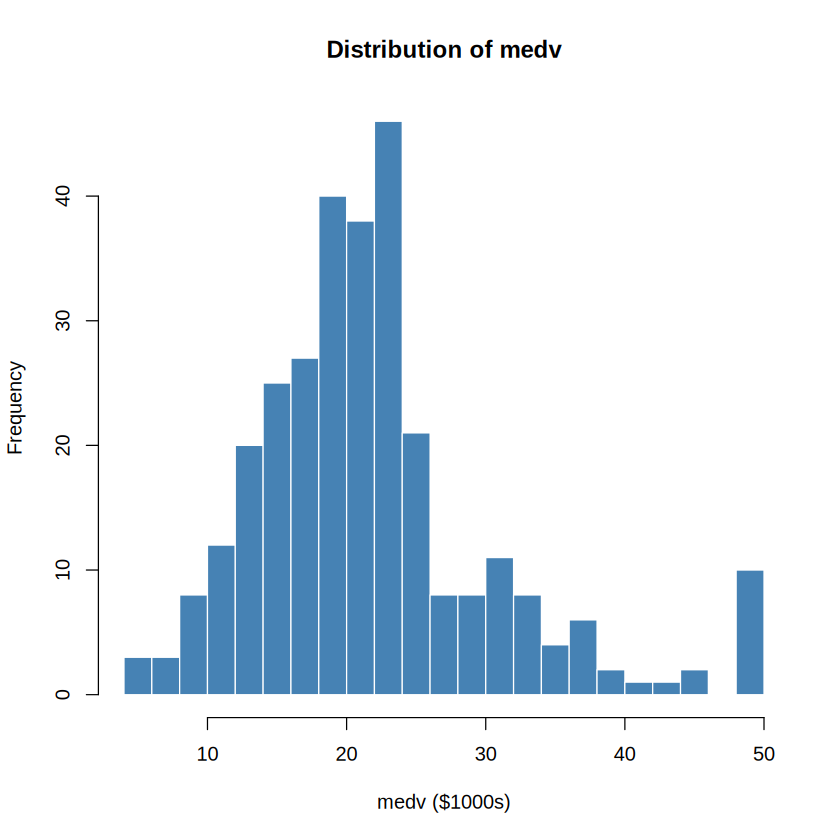

In [ ]:
hist(train$medv, breaks = 30, col = "steelblue", border = "white",
     main = "Distribution of medv", xlab = "medv ($1000s)")
cat("Rows with medv == 50:", sum(train$medv == 50), "<- values look capped (censored) at 50\n")

## 5. Which features relate to price?

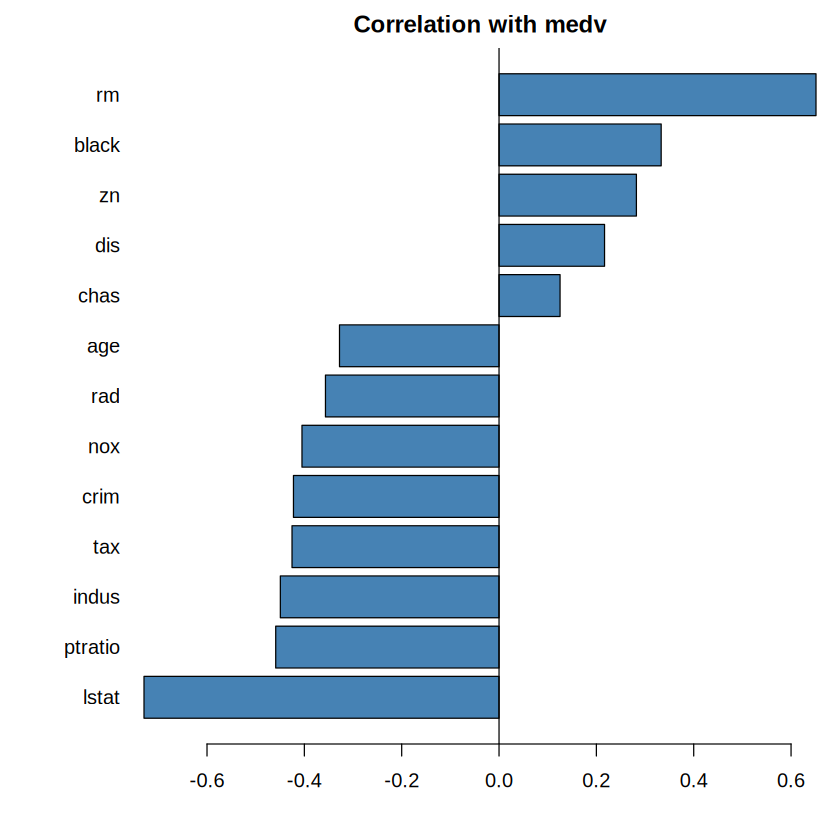

In [ ]:
features <- setdiff(names(train), c("ID", "medv"))
cors <- sort(cor(train[, features], train$medv)[, 1])
par(mar = c(4, 6, 2, 1))
barplot(cors, horiz = TRUE, las = 1, col = "steelblue", main = "Correlation with medv")
abline(v = 0)

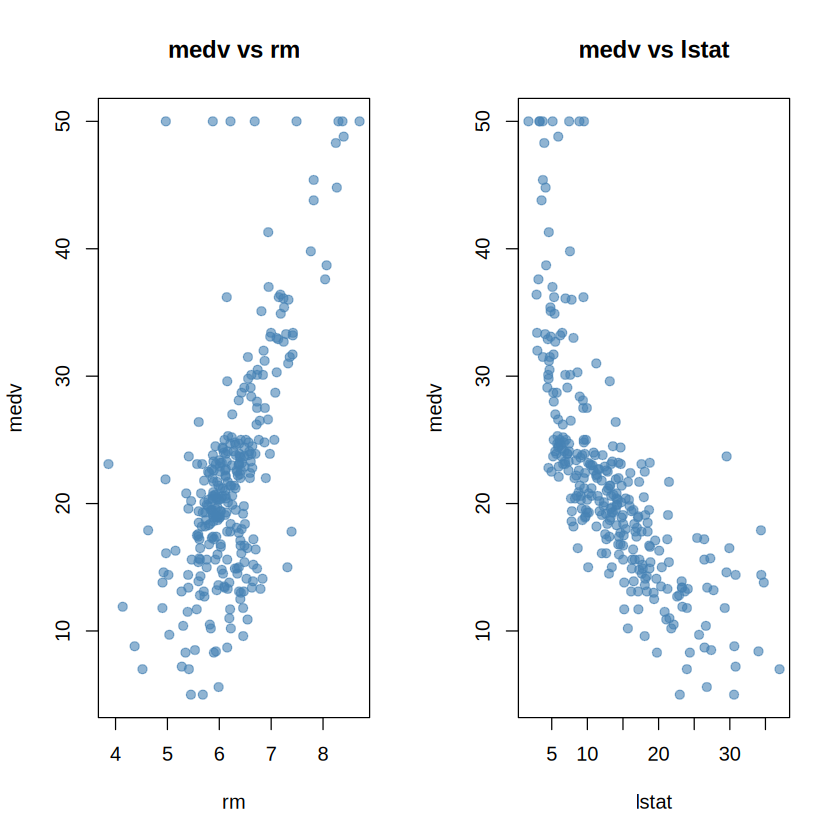

In [ ]:
par(mfrow = c(1, 2))
plot(medv ~ rm, data = train, pch = 19, col = adjustcolor("steelblue", 0.6), main = "medv vs rm")
plot(medv ~ lstat, data = train, pch = 19, col = adjustcolor("steelblue", 0.6), main = "medv vs lstat")
par(mfrow = c(1, 1))

## 6. Models with 5-fold cross-validation

Our test file has no answers, so we estimate performance by **cross-validation on the training set**.
Metric: **RMSE** (in $1000s, so lower is better). We write the CV loop ourselves so you can see every step.

In [ ]:
rmse <- function(obs, pred) sqrt(mean((obs - pred)^2))

set.seed(SEED)
folds <- sample(rep(1:5, length.out = nrow(train)))

cv_rmse <- function(fit_predict) {
  scores <- sapply(1:5, function(k) {
    tr <- train[folds != k, ]
    va <- train[folds == k, ]
    rmse(va$medv, fit_predict(tr, va))
  })
  c(CV_RMSE = mean(scores), SD = sd(scores))
}

fml <- reformulate(features, response = "medv")

models <- list(
  "Baseline (predict the mean)" = function(tr, va) rep(mean(tr$medv), nrow(va)),
  "Linear regression"           = function(tr, va) predict(lm(fml, data = tr), va),
  "Random forest"               = function(tr, va) {
    set.seed(SEED); predict(randomForest(fml, data = tr, ntree = 300), va)
  }
)
results <- t(sapply(models, cv_rmse))
round(results, 2)

,CV_RMSE,SD
Baseline (predict the mean),8.71,0.61
Linear regression,5.07,1.11
Random forest,3.52,0.87


### Linear regression on the full training set

In [ ]:
lin <- lm(fml, data = train)
summary(lin)


Call:
lm(formula = fml, data = train)

Residuals:
    Min      1Q  Median      3Q     Max 
-9.5731 -2.8457 -0.6892  1.5429 24.4959 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  40.891701   6.565729   6.228 1.65e-09 ***
crim         -0.129298   0.049824  -2.595 0.009937 ** 
zn            0.048536   0.022530   2.154 0.032038 *  
indus        -0.038439   0.077944  -0.493 0.622274    
chas          3.323372   1.247740   2.664 0.008165 ** 
nox         -17.504667   5.098457  -3.433 0.000683 ***
rm            3.007588   0.565152   5.322 2.06e-07 ***
age           0.008300   0.017307   0.480 0.631902    
dis          -1.547107   0.274297  -5.640 4.03e-08 ***
rad           0.335485   0.089424   3.752 0.000212 ***
tax          -0.012911   0.004945  -2.611 0.009502 ** 
ptratio      -0.848640   0.170046  -4.991 1.04e-06 ***
black         0.007751   0.003378   2.295 0.022470 *  
lstat        -0.557953   0.064601  -8.637 3.93e-16 ***
---
Signif. codes:  0 ‘***’

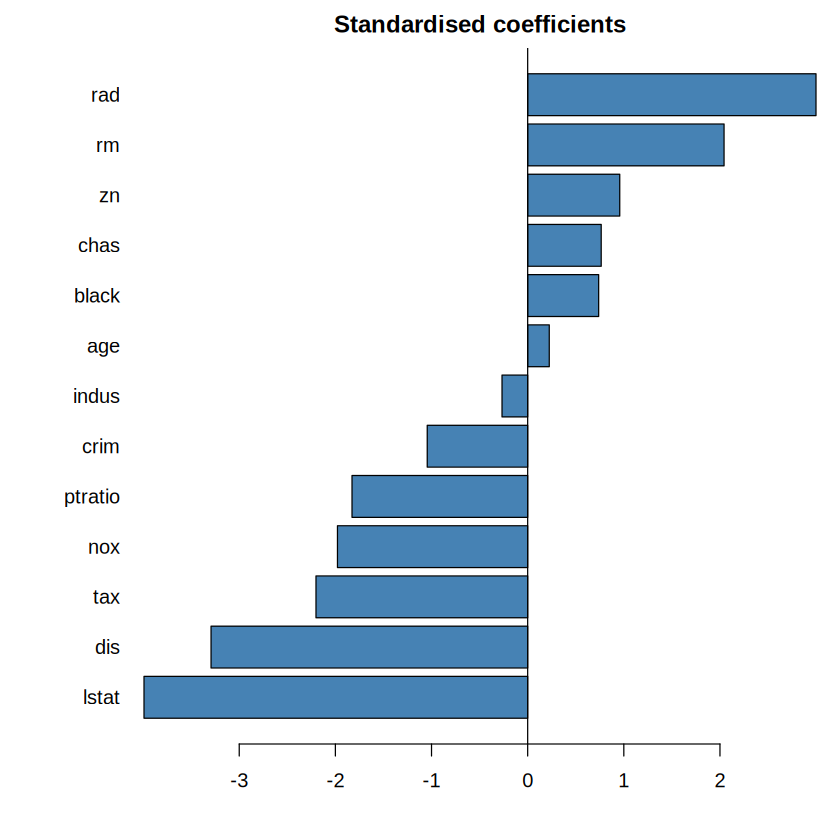

In [ ]:
# Standardised coefficients, comparable across features
lin_std <- lm(medv ~ ., data = data.frame(scale(train[, features]), medv = train$medv))
par(mar = c(4, 6, 2, 1))
barplot(sort(coef(lin_std)[-1]), horiz = TRUE, las = 1, col = "steelblue",
        main = "Standardised coefficients")
abline(v = 0)

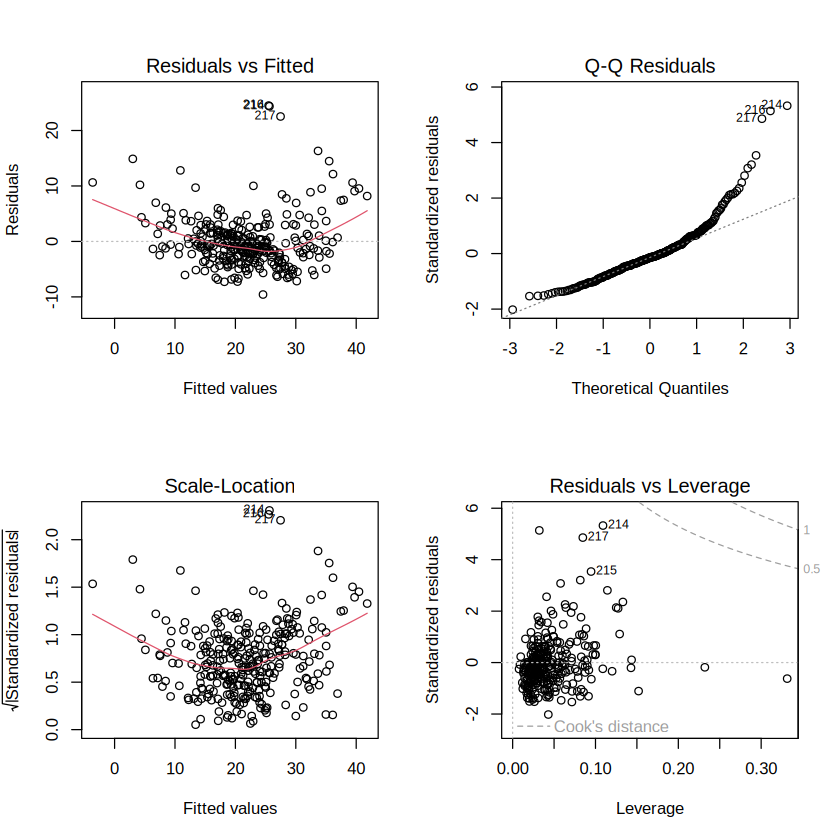

In [ ]:
par(mfrow = c(2, 2)); plot(lin); par(mfrow = c(1, 1))   # regression diagnostics

### Random forest variable importance


Call:
 randomForest(formula = fml, data = train, ntree = 300, importance = TRUE) 
               Type of random forest: regression
                     Number of trees: 300
No. of variables tried at each split: 4

          Mean of squared residuals: 12.13937
                    % Var explained: 83.96

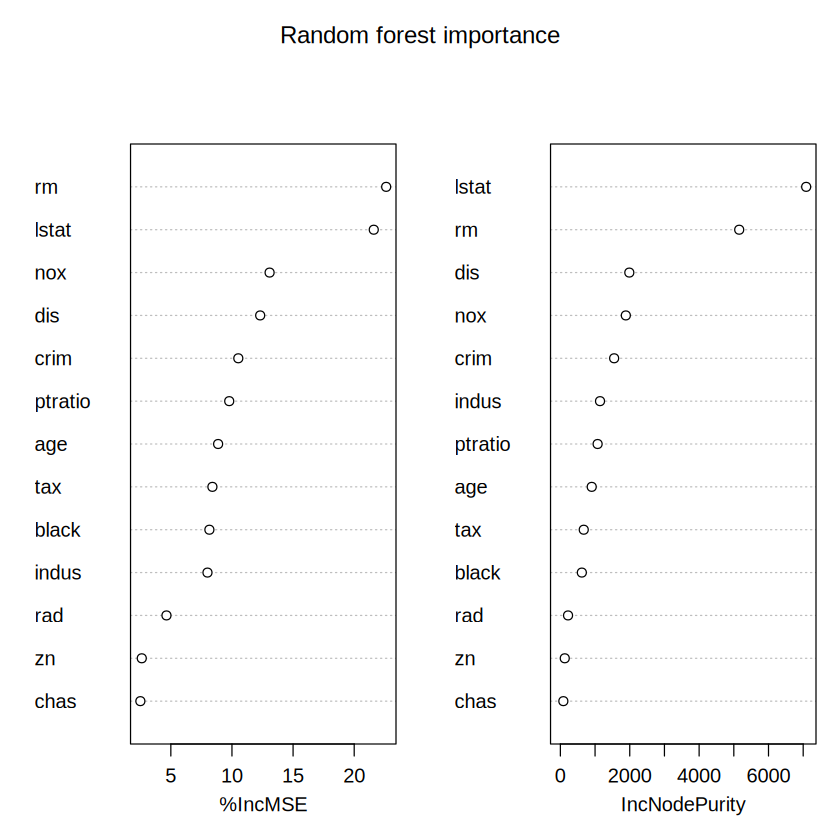

In [ ]:
set.seed(SEED)
rf <- randomForest(fml, data = train, ntree = 300, importance = TRUE)
rf
varImpPlot(rf, main = "Random forest importance")

## 7. Predict the test set and save

In [ ]:
best <- rf   # change this if another model does better for you
test_pred <- data.frame(ID = test$ID, medv = round(predict(best, test), 2))
write.csv(test_pred, "predictions.csv", row.names = FALSE)
head(test_pred)
cat("Saved predictions.csv with", nrow(test_pred), "rows\n")
if (IN_COLAB) cat("In Colab: open the folder icon on the left, right-click predictions.csv, Download\n")

,ID,medv
,<int>,<dbl>
1,1,27.26
2,2,23.37
3,3,33.58
4,8,17.38
5,15,19.94
6,16,20.73


Saved predictions.csv with 202 rows
In Colab: open the folder icon on the left, right-click predictions.csv, Download


## 8. Your turn
1. Fit the linear model on `log(medv)` instead of `medv`. Does CV RMSE improve when you transform predictions back with `exp()`?
2. Add `I(lstat^2)` or `log(lstat)` to the formula. Why might that help a linear model?
3. Drop the `black` variable. How much does performance change? What does that tell you?
4. Try `step(lin)` for variable selection, or tune `mtry` / `nodesize` in the random forest.
5. What should we do with the 8 houses capped at `medv = 50`?

Write a short note under each answer explaining what you found.